# Images and numerical boundary sources in three dimensions

This notebook solves a source-collocation approximation with OneSimulation dense linear algebra. All physical field evaluations lie outside a grounded sphere. An exact image construction supplies an independent reference. Change `--sources`, `--distance`, and `--source-radius` in the options list below.

The source points are numerical devices inside the excluded metal, not the physical surface-charge distribution. A tiny linear residual only certifies the fitted points. The reported withheld-point residual measures a different error; refine the source set and compare both.

Sources: 48; d/a=2; source radius/a=0.65
Linear residual: 2.220e-16; withheld boundary error: 4.184726e-01 V
Induced charge: -0.49918756 nC; exact: -0.50000000 nC


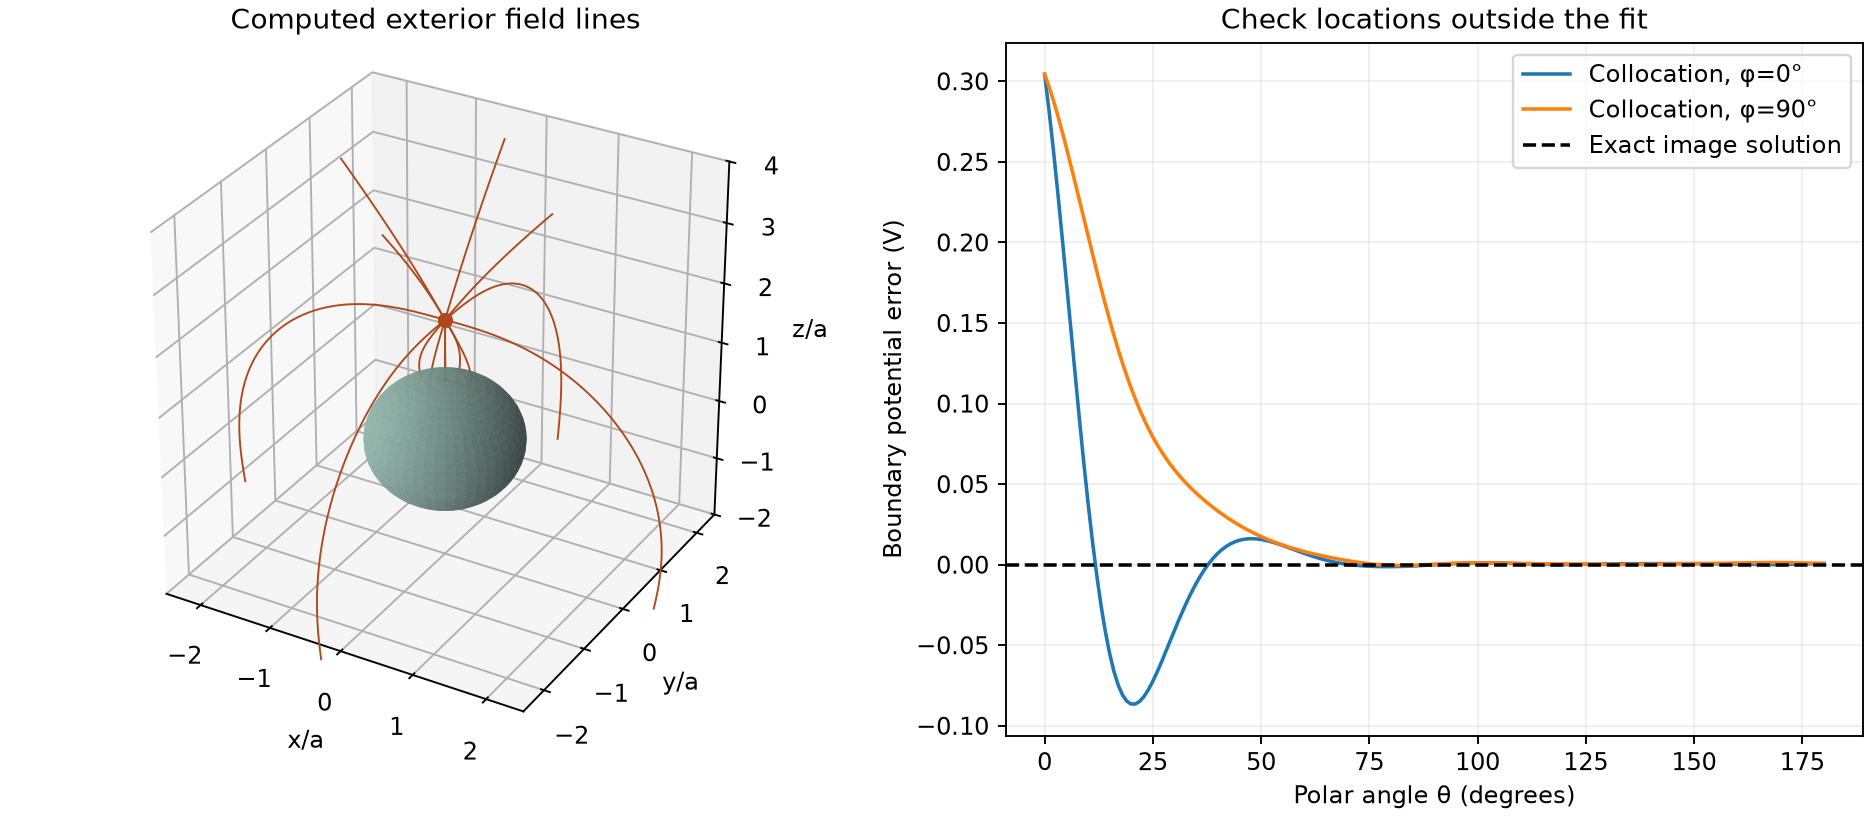

In [1]:
"""Grounded sphere: a 3D source-collocation solve and an independent image solution."""
import argparse
import numpy as np
import matplotlib.pyplot as plt
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense

parser = argparse.ArgumentParser(description=__doc__)
parser.add_argument('--sources', type=int, default=48)
parser.add_argument('--distance', type=float, default=2.0, help='Real-charge distance / sphere radius')
parser.add_argument('--source-radius', type=float, default=.65, help='Fictitious-source radius / sphere radius')
args = parser.parse_args([])  # Example: ["--sources", "96", "--distance", "2"]
if not 24 <= args.sources <= 96 or not 1.5 <= args.distance <= 3 or not .45 <= args.source_radius <= .85:
    parser.error('Use 24–96 sources, distance 1.5–3, and source radius 0.45–0.85')

def fibonacci_sphere(n, offset=0.0):
    j = np.arange(n)
    z = 1 - 2*(j+.5)/n
    phi = j*np.pi*(3-np.sqrt(5))+offset
    return np.column_stack([np.sqrt(1-z*z)*np.cos(phi),np.sqrt(1-z*z)*np.sin(phi),z])

boundary = fibonacci_sphere(args.sources)
sources = args.source_radius*boundary
charge = np.array([0.,0.,args.distance])
influence = 1/np.linalg.norm(boundary[:,None,:]-sources[None,:,:],axis=2)
rhs = -1/np.linalg.norm(boundary-charge,axis=1)
weights = np.asarray(solve_dense(influence,rhs))
factor = 8.9875517923  # q/(4*pi*eps0), for q=1 nC and radius=1 m

def potential(points):
    points=np.atleast_2d(points)
    return factor*(1/np.linalg.norm(points-charge,axis=1)
                   + (1/np.linalg.norm(points[:,None,:]-sources[None,:,:],axis=2))@weights)

def exact(points):
    points=np.atleast_2d(points)
    image=np.array([0.,0.,1/args.distance])
    return factor*(1/np.linalg.norm(points-charge,axis=1)
                   -1/args.distance/np.linalg.norm(points-image,axis=1))

def field(point):
    real=point-charge
    delta=point-sources
    return real/np.linalg.norm(real)**3 + (weights[:,None]*delta/np.linalg.norm(delta,axis=1)[:,None]**3).sum(axis=0)

check = fibonacci_sphere(1201,.37)
boundary_error=float(np.max(np.abs(potential(check))))
algebraic_error=float(np.max(np.abs(influence@weights-rhs)))
print(f'Sources: {args.sources}; d/a={args.distance:g}; source radius/a={args.source_radius:g}')
print(f'Linear residual: {algebraic_error:.3e}; withheld boundary error: {boundary_error:.6e} V')
print(f'Induced charge: {weights.sum():.8f} nC; exact: {-1/args.distance:.8f} nC')
assert algebraic_error < 1e-9

fig = plt.figure(figsize=(11,4.8),layout='constrained')
ax=fig.add_subplot(121,projection='3d')
theta=np.linspace(0,np.pi,25);phi=np.linspace(0,2*np.pi,49)
T,P=np.meshgrid(theta,phi)
ax.plot_surface(np.sin(T)*np.cos(P),np.sin(T)*np.sin(P),np.cos(T),color='#94b8af',alpha=.85,linewidth=0)
for angle in [np.pi/6,np.pi/2,5*np.pi/6,np.pi]:
    for azimuth in [0,np.pi/2,np.pi,3*np.pi/2]:
        p=charge+.08*np.array([np.sin(angle)*np.cos(azimuth),np.sin(angle)*np.sin(azimuth),np.cos(angle)])
        path=[p.copy()]
        for _ in range(160):
            e=field(p);p=p+.035*e/np.linalg.norm(e);path.append(p.copy())
            if np.linalg.norm(p)<1.015 or np.linalg.norm(p)>4.4:break
        curve=np.array(path);ax.plot(*curve.T,color='#ad491d',linewidth=.8)
ax.scatter(*charge,color='#ad491d',s=30)
ax.set(xlabel='x/a',ylabel='y/a',zlabel='z/a',title='Computed exterior field lines')
ax.set_box_aspect([1,1,1]);ax.set(xlim=(-2.5,2.5),ylim=(-2.5,2.5),zlim=(-2,4))
ax=fig.add_subplot(122)
angles=np.linspace(0,np.pi,181)
for azimuth in [0,np.pi/2]:
    points=np.column_stack([np.sin(angles)*np.cos(azimuth),np.sin(angles)*np.sin(azimuth),np.cos(angles)])
    ax.plot(np.rad2deg(angles),potential(points),label=f'Collocation, φ={np.rad2deg(azimuth):g}°')
ax.axhline(0,color='black',linestyle='--',label='Exact image solution')
ax.set(xlabel='Polar angle θ (degrees)',ylabel='Boundary potential error (V)',title='Check locations outside the fit')
ax.legend();ax.grid(alpha=.2)
fig.savefig('complete-spatial-sphere.png',dpi=170)


## Six related boundary experiments

The next cell collects the exact reduced formulas from the chapter. Change the parameters in each block to reproduce the browser plots. These analytic comparisons use NumPy; the spatial collocation above uses the OneSimulation solver. Forces, capacitances and reflection coefficients have distinct units and therefore get separate axes.

Wedge bisector force (nN): [-6.04547429e+00 -4.13590306e-16]
Cylinder grounded attraction at d/a=2.5 (µN/m): 0.8559573135523809
Dielectric force at d=1 mm (nN): 18.72406623395833
Film zero-reflection wavelength (mm): 11.438403469520507


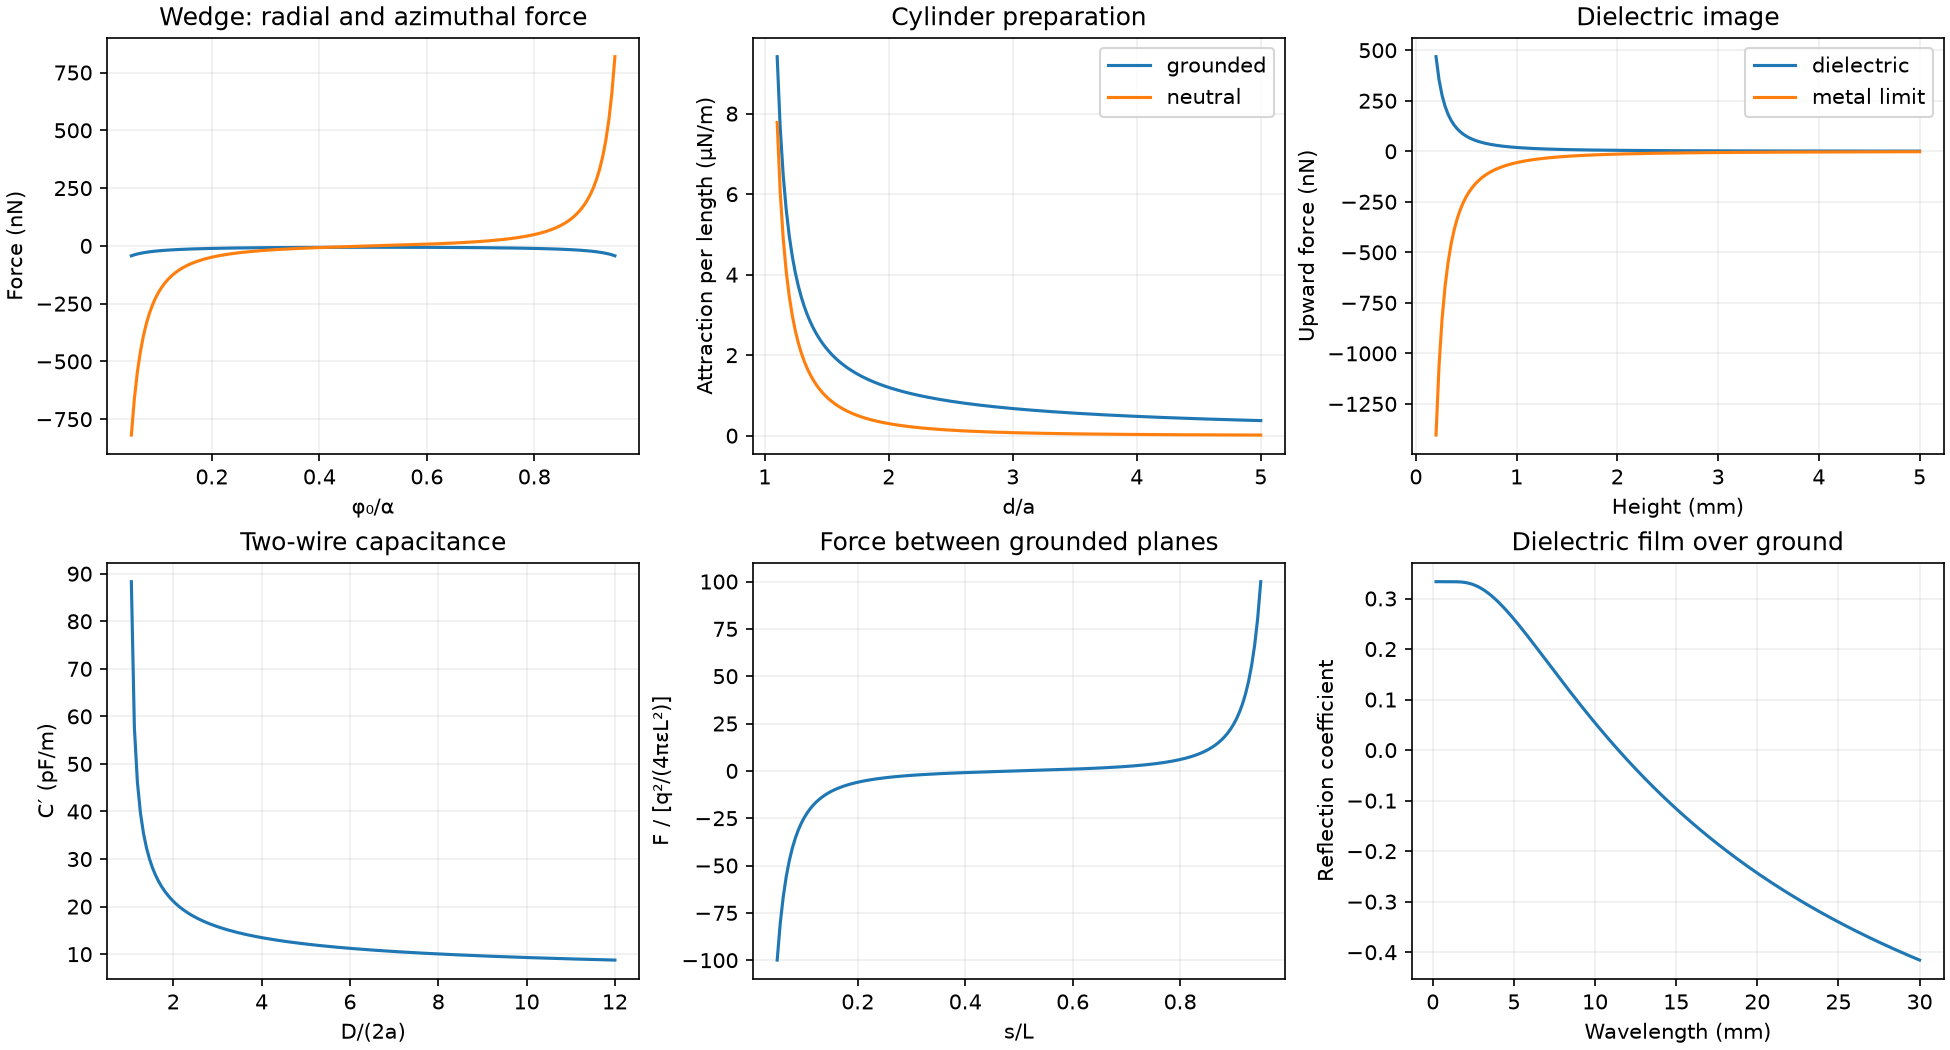

In [2]:
# Companion exact boundary constructions; SI values with labelled plotting units.
import numpy as np
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
k = 8.9875517923e9
# Grounded wedge of angle pi/m: q=1 nC, radius=1 m.
m, radius = 3, 1.0
fractions = np.linspace(.05,.95,161)
def wedge_force(f):
    phi=f*np.pi/m; p=radius*np.array([np.cos(phi),np.sin(phi)]); force=np.zeros(2)
    for j in range(m):
        for sign in [-1,1]:
            if j==0 and sign==1: continue
            angle=sign*phi+2*j*np.pi/m
            v=p-radius*np.array([np.cos(angle),np.sin(angle)])
            force += k*1e-18*sign*v/np.linalg.norm(v)**3
    return 1e9*np.array([force@[np.cos(phi),np.sin(phi)],force@[-np.sin(phi),np.cos(phi)]])
forces=np.array([wedge_force(f) for f in fractions])
axes[0,0].plot(fractions,forces);axes[0,0].set(xlabel="φ₀/α",ylabel="Force (nN)",title="Wedge: radial and azimuthal force")
# Infinite cylinder: a=10 mm, lambda=1 nC/m.
a, line_charge = .01, 1e-9
s=np.linspace(1.1,5,161); coefficient=2*k*line_charge**2/a*1e6
axes[0,1].plot(s,coefficient*s/(s*s-1),label="grounded")
axes[0,1].plot(s,coefficient/(s*(s*s-1)),label="neutral")
axes[0,1].set(xlabel="d/a",ylabel="Attraction per length (µN/m)",title="Cylinder preparation");axes[0,1].legend()
# Dielectric interface, upper epsilon=4 epsilon0, q=10 pC.
ratio,q = .5,10e-12
d=np.linspace(.2,5,161);eta=(1-ratio)/(1+ratio)
factor=k*q*q/(4*4*(d*1e-3)**2)*1e9
axes[0,2].plot(d,eta*factor,label="dielectric");axes[0,2].plot(d,-factor,label="metal limit")
axes[0,2].set(xlabel="Height (mm)",ylabel="Upward force (nN)",title="Dielectric image");axes[0,2].legend()
# Two conductors: charge per length divided by their full voltage difference.
epsilon_r=1;spacing=np.linspace(1.05,12,161)
axes[1,0].plot(spacing,27.816251386*epsilon_r/np.arccosh(spacing))
axes[1,0].set(xlabel="D/(2a)",ylabel="C′ (pF/m)",title="Two-wire capacitance")
# Symmetric image truncation between two grounded parallel planes.
order=12;position=np.linspace(.05,.95,161)
force=np.array([-sum((2*u-2*n)/abs(2*u-2*n)**3 for n in range(-order,order+2)) for u in position])
axes[1,1].plot(position,force);axes[1,1].set(xlabel="s/L",ylabel="F / [q²/(4πεL²)]",title="Force between grounded planes")
# Film thickness and wavelength measured in mm; their ratio is dimensionless.
ratio,thickness=.5,1.0;wavelength=np.linspace(.2,30,161)
b=ratio/np.tanh(2*np.pi*thickness/wavelength)
axes[1,2].plot(wavelength,(1-b)/(1+b));axes[1,2].set(xlabel="Wavelength (mm)",ylabel="Reflection coefficient",title="Dielectric film over ground")
for ax in axes.flat: ax.grid(alpha=.2)
fig.savefig("complete-spatial-boundaries.png",dpi=150)
print("Wedge bisector force (nN):", wedge_force(.5))
print("Cylinder grounded attraction at d/a=2.5 (µN/m):",coefficient*2.5/(2.5**2-1))
print("Dielectric force at d=1 mm (nN):",k*q*q*eta/(16e-6)*1e9)
print("Film zero-reflection wavelength (mm):",2*np.pi*thickness/np.arctanh(ratio))
